# 사람동작 영상(이미지 tar) → 그림 애니메이션용 동작 소스 (2D 관절 시퀀스)
목적: 실제 사람 영상에서 **평면 동작의 관절 움직임**을 뽑아 그림에 입힐 동작 데이터로 쓴다. (학습 데이터 용도 아님)

데이터 특징 (확인 결과)
- 폴더 하나 = 한 테이크를 **한 카메라**로 찍은 것 (예: `1-1_003-C08` = 동작 1-1, 테이크 003, 카메라 C08). 같은 테이크를 여러 카메라로 찍음
- 이미지는 원본 영상의 **10프레임마다 1장** (`_009, _019…`) → 30fps 기준 약 3fps

처리
1. 프레임을 순서대로 추출 (같은 사람 추적, 원본+좌우반전 평균, 일치하는 관절만 신뢰)
2. 파일 번호로 실제 시간을 계산하고, 듬성듬성한 샘플 사이를 **출력 fps로 보간**(PCHIP: 꼭짓점을 넘는 출렁임 없음)
3. 같은 테이크의 카메라 중 **정면을 향한 가장 정면 카메라**를 자동 선택 (뒷모습은 좌우가 뒤집혀서 제외)
4. 골반 기준 정규화 좌표 + 뼈 각도 저장, 품질 표시, 확인용 mp4

결과: `OUT_DIR/motions/*.json`, `OUT_DIR/previews/*.mp4`, `OUT_DIR/summary.json`

In [ ]:
!pip install -q rtmlib tqdm matplotlib scipy imageio imageio-ffmpeg
# rtmlib이 CPU용 onnxruntime을 같이 설치해서 GPU가 안 쓰임 → 둘 다 지우고 GPU판만 설치
!pip uninstall -y -q onnxruntime onnxruntime-gpu
!pip install -q onnxruntime-gpu
# 이미 onnxruntime을 import한 세션이면: 런타임 → 세션 다시 시작 후 1번 셀부터

## 1. 설정

In [ ]:
from pathlib import Path

WORK_DIR = Path("/content/work")        # image_1-N.tar 업로드 위치 (하위 폴더도 찾음)
OUT_DIR  = Path("/content/out_motion")
WORK_DIR.mkdir(parents=True, exist_ok=True)

# --- 시간 ---
SRC_FPS = 30           # 원본 영상 fps (데이터 설명서 확인). 파일 번호 _009, _019… = 원본 프레임 번호
FILE_STEP = 10         # 파일 번호 간격 (번호를 못 읽을 때만 사용)
OUTPUT_FPS = 15        # 저장할 동작 fps. 듬성듬성한 원본 샘플(약 3fps) 사이를 보간해서 채움

# --- 관절 신뢰도 / 보간 ---
KPT_THR = 0.3          # 관절 점수 하한
FLIP_THR = 0.05        # 원본/좌우반전 예측 차이 허용치 (bbox 긴 변 대비). 많이 빠지면 0.08
MAX_GAP_SEC = 0.7      # 신뢰 샘플 사이가 이보다 길면 보간하지 않고 비움 (10프레임 간격이면 샘플 1개 빠진 것까지 허용)

# --- 품질 ---
MIN_TORSO_RATIO = 0.8  # 몸통이 신뢰되는 샘플 비율 하한 (미만이면 usable=False)
PLANAR_MIN = 0.6       # 어깨폭이 '가장 정면일 때 폭'의 60% 미만이면 몸을 돌린 샘플로 봄

# --- 실행 ---
MODE = "performance"
DEVICE = "cuda"
MAX_SEQ = 12           # 처음엔 12개(테이크 몇 개 × 카메라)로 확인하고 None으로
PREVIEW = "best"       # 미리보기 mp4: "best"(테이크별 고른 카메라만) / "all" / None

## 2. tar 확인
`/content/work`에 image_1-N.tar를 업로드한 뒤 실행.

In [ ]:
tars = sorted(WORK_DIR.rglob("*.tar"))
print(f"{WORK_DIR} 안의 tar: {len(tars)}개")
for p in tars:
    print(" -", p.name, f"{p.stat().st_size / 1e9:.2f}GB")
if not tars:
    raise SystemExit("tar가 없음: 왼쪽 파일 패널의 /content/work 에 image_1-N.tar를 업로드")

import torch
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "없음 (런타임 유형을 GPU로)")

/content/work 안의 tar: 5개
 - image_1-1.tar 0.76GB
 - image_1-11.tar 0.79GB
 - image_1-23.tar 0.79GB
 - image_1-31.tar 0.79GB
 - image_1-5.tar 0.76GB
GPU: NVIDIA L4


## 3. 모델 로드 (GPU 사용 확인)

In [ ]:
import torch                      # CUDA/cuDNN 라이브러리를 먼저 올려 두면 onnxruntime GPU가 찾기 쉬움
import onnxruntime as ort
try:
    ort.preload_dlls()            # onnxruntime 1.21+
except Exception:
    pass
print("onnxruntime", ort.__version__, ort.get_available_providers())

from rtmlib import Body
body = Body(mode=MODE, backend="onnxruntime", device=DEVICE, to_openpose=False)

used = body.pose_model.session.get_providers()
print("포즈 모델 실행 장치:", used)
if DEVICE == "cuda":
    assert "CUDAExecutionProvider" in used, "GPU를 못 쓰고 CPU로 돌고 있음 → 1번 설치 셀 실행 후 세션 다시 시작"

onnxruntime 1.31.1 ['TensorrtExecutionProvider', 'CUDAExecutionProvider', 'CPUExecutionProvider']
load /root/.cache/rtmlib/hub/checkpoints/yolox_x_8xb8-300e_humanart-a39d44ed.onnx with onnxruntime backend
load /root/.cache/rtmlib/hub/checkpoints/rtmpose-x_simcc-body7_pt-body7_700e-384x288-71d7b7e9_20230629.onnx with onnxruntime backend
포즈 모델 실행 장치: ['CUDAExecutionProvider', 'CPUExecutionProvider']


## 4. 함수

In [ ]:
import json, re, tarfile
from collections import defaultdict
from pathlib import Path
import cv2
import numpy as np
from scipy.interpolate import PchipInterpolator

IMAGE_EXT = {".jpg", ".jpeg", ".png"}
FLIP = [0, 2, 1, 4, 3, 6, 5, 8, 7, 10, 9, 12, 11, 14, 13, 16, 15]          # COCO17 좌우 짝
J15 = ['nose', 'neck', 'r_sho', 'r_elb', 'r_wri', 'l_sho', 'l_elb', 'l_wri',
       'pelvis', 'r_hip', 'r_knee', 'r_ank', 'l_hip', 'l_knee', 'l_ank']
SRC = [0, (5, 6), 6, 8, 10, 5, 7, 9, (11, 12), 12, 14, 16, 11, 13, 15]      # J15 ← COCO17
TORSO = [5, 6, 11, 12]
BONES = [(8, 1, 'spine'), (1, 0, 'head'),
         (1, 2, 'r_shoulder'), (2, 3, 'r_upper_arm'), (3, 4, 'r_forearm'),
         (1, 5, 'l_shoulder'), (5, 6, 'l_upper_arm'), (6, 7, 'l_forearm'),
         (8, 9, 'r_hip'), (9, 10, 'r_thigh'), (10, 11, 'r_shin'),
         (8, 12, 'l_hip'), (12, 13, 'l_thigh'), (13, 14, 'l_shin')]
RIGHT = {'r_shoulder', 'r_upper_arm', 'r_forearm', 'r_hip', 'r_thigh', 'r_shin'}
SEQ_RE = re.compile(r'(?P<action>\d+-\d+)_(?P<take>\d+)-(?P<cam>C\d+)')     # 예) 1-1_003-C08


def natkey(s):
    return [int(t) if t.isdigit() else t for t in re.split(r'(\d+)', s)]


def frame_no(name):
    """파일 이름 끝 번호 = 원본 영상 프레임 번호 (예: 1-1_003-C08_019.jpg → 19)"""
    m = re.search(r'(\d+)$', Path(name).stem)
    return int(m.group(1)) if m else None


def seq_meta(seq):
    m = SEQ_RE.search(seq.split('/')[-1])
    return m.groupdict() if m else dict(action='?', take=seq, cam='?')


def list_sequences(src):
    """작은 tar 안의 폴더 = 한 카메라의 영상 1개. → {seq_id: (tar_path, [프레임 이름, 번호 순])}"""
    seqs = {}
    for tp in sorted(Path(src).rglob("*.tar"), key=lambda p: natkey(p.name)):
        d = defaultdict(list)
        with tarfile.open(tp) as tf:
            for m in tf.getmembers():
                n = m.name
                if (m.isfile() and Path(n).suffix.lower() in IMAGE_EXT
                        and "__MACOSX" not in n and not Path(n).name.startswith("._")):
                    d[Path(n).parent.as_posix()].append(n)
        for s, names in d.items():
            seqs[f"{tp.stem}/{Path(s).name}"] = (tp, sorted(names, key=lambda n: (frame_no(n) or 0, n)))
    return dict(sorted(seqs.items(), key=lambda kv: natkey(kv[0])))


def read_frames(tar_path, names):
    with tarfile.open(tar_path) as tf:
        mm = {m.name: m for m in tf.getmembers()}
        for i, n in enumerate(names):
            data = tf.extractfile(mm[n]).read()
            yield i, n, cv2.imdecode(np.frombuffer(data, np.uint8), cv2.IMREAD_COLOR)


def iou(a, b):
    x1, y1 = max(a[0], b[0]), max(a[1], b[1])
    x2, y2 = min(a[2], b[2]), min(a[3], b[3])
    inter = max(0, x2 - x1) * max(0, y2 - y1)
    union = (a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1]) - inter
    return inter / union if union > 0 else 0.0


def track_box(frame, prev):
    """첫 프레임은 가장 큰 사람, 이후는 직전 박스와 가장 많이 겹치는 사람."""
    boxes = body.det_model(frame)
    if boxes is None or len(boxes) == 0:
        return prev, False
    boxes = np.asarray(boxes)[:, :4]
    if prev is None:
        i = int(((boxes[:, 2] - boxes[:, 0]) * (boxes[:, 3] - boxes[:, 1])).argmax())
    else:
        ious = [iou(b, prev) for b in boxes]
        i = int(np.argmax(ious))
        if ious[i] < 0.1:
            return prev, False
    return boxes[i], True


def predict_with_flip(frame, box):
    """원본 + 좌우반전 예측의 평균. 두 예측이 일치하는 관절만 신뢰."""
    H, W = frame.shape[:2]
    k, s = body.pose_model(frame, bboxes=[box])
    k, s = np.asarray(k[0], float), np.asarray(s[0], float)
    fbox = np.array([W - box[2], box[1], W - box[0], box[3]])
    kf, sf = body.pose_model(np.ascontiguousarray(frame[:, ::-1]), bboxes=[fbox])
    kf, sf = np.asarray(kf[0], float)[FLIP], np.asarray(sf[0], float)[FLIP]
    kf[:, 0] = W - kf[:, 0]
    scale = max(box[2] - box[0], box[3] - box[1])
    err = np.linalg.norm(k - kf, axis=1) / scale
    return (k + kf) / 2, (s >= KPT_THR) & (sf >= KPT_THR) & (err < FLIP_THR)


def to_j15_seq(K, OK):
    T = len(K)
    K15, OK15 = np.full((T, 15, 2), np.nan), np.zeros((T, 15), bool)
    for j, src in enumerate(SRC):
        idx = list(src) if isinstance(src, tuple) else [src]
        K15[:, j] = K[:, idx].mean(1)
        OK15[:, j] = OK[:, idx].all(1)
    K15[~OK15] = np.nan
    return K15, OK15


def resample(t_src, K, t_out, max_gap):
    """관절별로 신뢰 샘플만 써서 PCHIP 보간 (꼭짓점을 넘어서는 출렁임 없음).
    두 신뢰 샘플 사이가 max_gap(초)보다 길면 그 구간은 비움.
    conf: 1 = 바로 이웃한 두 원본 샘플 사이, 0.5 = 빠진 샘플을 건너뛴 구간, 0 = 없음"""
    out = np.full((len(t_out), K.shape[1], 2), np.nan)
    conf = np.zeros((len(t_out), K.shape[1]))
    for j in range(K.shape[1]):
        idx = np.where(~np.isnan(K[:, j, 0]))[0]
        if len(idx) < 2:
            continue
        tv = t_src[idx]
        f = PchipInterpolator(tv, K[idx, j], axis=0, extrapolate=False)
        b = np.clip(np.searchsorted(tv, t_out, side='left'), 1, len(tv) - 1)
        a = b - 1
        inside = (t_out >= tv[0]) & (t_out <= tv[-1]) & (tv[b] - tv[a] <= max_gap + 1e-9)
        out[inside, j] = f(t_out[inside])
        conf[inside, j] = np.where(idx[b[inside]] - idx[a[inside]] == 1, 1.0, 0.5)
    return out, conf


def bone_angles(K):
    """뼈마다 화면 기준 각도(도, x축 기준, y는 아래가 +). 시간축으로 360° 점프 없게 unwrap."""
    A = np.full((len(K), len(BONES)), np.nan)
    for b, (p, c, _) in enumerate(BONES):
        d = K[:, c] - K[:, p]
        a = np.arctan2(d[:, 1], d[:, 0])
        ok = ~np.isnan(a)
        if ok.any():
            a[ok] = np.unwrap(a[ok])
        A[:, b] = np.degrees(a)
    return A


def nan_to_none(x, nd=3):
    if isinstance(x, np.ndarray):
        x = x.tolist()
    if isinstance(x, list):
        return [nan_to_none(v, nd) for v in x]
    if isinstance(x, float):
        return None if np.isnan(x) else round(x, nd)
    return x


def draw_skeleton(img, k, conf, thick=3):
    conf = np.where(np.isfinite(k).all(1), conf, 0)
    for p, c, name in BONES:
        if conf[p] > 0 and conf[c] > 0:
            col = (60, 60, 230) if name in RIGHT else (230, 120, 40) if name.startswith('l_') else (80, 200, 80)
            cv2.line(img, tuple(int(v) for v in k[p]), tuple(int(v) for v in k[c]), col, thick, cv2.LINE_AA)
    for j in range(15):
        if conf[j] > 0:
            cv2.circle(img, tuple(int(v) for v in k[j]), thick + 1, (0, 200, 255) if conf[j] == 1 else (160, 160, 160), -1)
    return img

## 5. 동작 추출 + 테이크별 카메라 선택
★ = 그 테이크에서 고른 카메라. O/X = 사용 가능 여부, front/back = 몸이 향한 방향, 정면도 = 어깨폭/몸통길이(클수록 정면).

In [ ]:
import imageio
from tqdm.auto import tqdm
MOT_DIR, PRV_DIR = OUT_DIR / "motions", OUT_DIR / "previews"
MOT_DIR.mkdir(parents=True, exist_ok=True); PRV_DIR.mkdir(exist_ok=True)

seqs = list_sequences(WORK_DIR)
todo = list(seqs)[:MAX_SEQ] if MAX_SEQ else list(seqs)
print(f"시퀀스 {len(seqs)}개 중 {len(todo)}개 처리")
res = {}
for seq in tqdm(todo, desc="sequences"):
    tp, names = seqs[seq]
    nums = [frame_no(n) for n in names]
    fn = np.array(nums if None not in nums else range(0, len(names) * FILE_STEP, FILE_STEP), float)
    t_src = (fn - fn[0]) / SRC_FPS                       # 파일 번호 → 실제 시간(초). 10프레임 간격이면 0.33초 간격
    T = len(names)
    K = np.full((T, 17, 2), np.nan); OK = np.zeros((T, 17), bool)
    box, size = None, None
    for i, n, frame in read_frames(tp, names):
        if frame is None:
            continue
        size = frame.shape[1], frame.shape[0]
        box, found = track_box(frame, box)
        if box is None:
            continue
        k, ok = predict_with_flip(frame, box)
        K[i], OK[i] = k, ok & found
    K15_raw, OK15 = to_j15_seq(K, OK)

    # 원본 샘플 기준 품질/방향
    torso_len = np.linalg.norm(K15_raw[:, 1] - K15_raw[:, 8], axis=1)
    ratio = np.linalg.norm(K15_raw[:, 2] - K15_raw[:, 5], axis=1) / torso_len     # 어깨폭/몸통길이
    has = np.isfinite(ratio).any()
    frontal = float(np.nanmedian(ratio)) if has else 0.0                           # 클수록 정면(또는 뒷면)
    facing = "front" if has and np.nanmedian(K15_raw[:, 5, 0] - K15_raw[:, 2, 0]) > 0 else "back"  # 정면이면 오른어깨가 화면 왼쪽
    widest = float(np.nanpercentile(ratio, 95)) if has else 0.0                      # 이 사람이 가장 정면일 때 폭
    planar = float(np.nanmean(ratio / widest >= PLANAR_MIN)) if widest >= 0.3 else 0.0  # 몸을 돌리지 않은 프레임 비율

    # 출력 fps로 보간 (원본 샘플이 듬성듬성해도 매끄러운 동작)
    t_out = np.arange(0, t_src[-1] + 1e-9, 1 / OUTPUT_FPS)
    K15, conf = resample(t_src, K15_raw, t_out, MAX_GAP_SEC)
    scale = float(np.nanmedian(np.linalg.norm(K15[:, 1] - K15[:, 8], axis=1)))
    root = K15[:, 8]
    fin = np.isfinite(root[:, 0])
    r0 = root[np.argmax(fin)] if fin.any() else np.zeros(2)
    norm = (K15 - root[:, None]) / scale                 # 골반 기준, 몸통 길이 단위
    root_rel = (root - r0) / scale                       # 골반 이동 (첫 프레임 기준)

    torso_ratio = float(OK[:, TORSO].all(1).mean())
    missing = float((conf == 0).mean())
    q = dict(torso_ratio=round(torso_ratio, 3), missing_ratio=round(missing, 3), frontal=round(frontal, 3),
             facing=facing, planar_ratio=round(planar, 3),
             usable=bool(torso_ratio >= MIN_TORSO_RATIO and missing <= 0.2))
    res[seq] = dict(meta=seq_meta(seq), q=q, tp=tp, names=names, t_src=t_src, size=size,
                    K15_raw=K15_raw, OK15=OK15, K15=K15, conf=conf, norm=norm, root_rel=root_rel)

# 같은 테이크(동작+촬영 번호)의 여러 카메라 중 정면을 향한 가장 정면 카메라 1개를 고름
groups = defaultdict(list)
for seq, r in res.items():
    groups[(seq.split('/')[0], r["meta"]["action"], r["meta"]["take"])].append(seq)
for g, ss in groups.items():
    cand = [s for s in ss if res[s]["q"]["usable"]]
    cand = [s for s in cand if res[s]["q"]["facing"] == "front"] or cand
    best = max(cand, key=lambda s: res[s]["q"]["frontal"]) if cand else None
    for s in ss:
        res[s]["q"]["best_camera"] = s == best

# 저장 + 미리보기
for seq, r in tqdm(res.items(), desc="save"):
    stem = re.sub(r"[^\w\-]+", "_", seq)
    rec = dict(seq=seq, **r["meta"], src_fps=SRC_FPS, src_frames=[frame_no(n) for n in r["names"]],
               fps=OUTPUT_FPS, n_frames=len(r["K15"]), image_size=r["size"], joints=J15,
               bones=[b[2] for b in BONES], bone_pairs=[[J15[p], J15[c]] for p, c, _ in BONES],
               keypoints_px=nan_to_none(np.concatenate([r["K15"], r["conf"][..., None]], -1), 2),
               keypoints_src_px=nan_to_none(r["K15_raw"], 2),
               keypoints_norm=nan_to_none(r["norm"], 4), root_rel=nan_to_none(r["root_rel"], 4),
               bone_angles_deg=nan_to_none(bone_angles(r["K15"]), 2), quality=r["q"])
    (MOT_DIR / f"{stem}.json").write_text(json.dumps(rec, ensure_ascii=False), encoding="utf-8")
    if PREVIEW == "all" or (PREVIEW == "best" and r["q"]["best_camera"]):
        dt = np.median(np.diff(r["t_src"])) if len(r["t_src"]) > 1 else 1.0
        if r["size"] is not None:                      # ① 원본 프레임 + 추출 관절 (원본 샘플 간격)
            pw = 640; ph = int(round(r["size"][1] * pw / r["size"][0] / 16)) * 16
            with imageio.get_writer(PRV_DIR / f"{stem}_frames.mp4", fps=1 / dt, macro_block_size=16) as w:
                for i, n, frame in read_frames(r["tp"], r["names"]):
                    if frame is not None:
                        draw_skeleton(frame, r["K15_raw"][i], r["OK15"][i].astype(float), 4)
                        w.append_data(cv2.cvtColor(cv2.resize(frame, (pw, ph)), cv2.COLOR_BGR2RGB))
        with imageio.get_writer(PRV_DIR / f"{stem}_motion.mp4", fps=OUTPUT_FPS, macro_block_size=16) as w:
            for i in range(len(r["norm"])):            # ② 보간된 동작 (막대 인형, 출력 fps)
                canvas = np.full((480, 480, 3), 255, np.uint8)
                pts = r["norm"][i] + r["root_rel"][i]
                draw_skeleton(canvas, pts * 90 + np.array([240, 250]), r["conf"][i])
                w.append_data(cv2.cvtColor(canvas, cv2.COLOR_BGR2RGB))

# 요약 (테이크별로 카메라 비교, ★ = 고른 카메라)
summary = []
for g, ss in sorted(groups.items(), key=lambda kv: natkey(str(kv[0]))):
    print(f"\n[{g[0]}] 동작 {g[1]} / 테이크 {g[2]}")
    for s in sorted(ss, key=natkey):
        q = res[s]["q"]
        summary.append(dict(seq=s, **res[s]["meta"], **q))
        print(f"  {'★' if q['best_camera'] else ' '} {res[s]['meta']['cam']:>4} | {'O' if q['usable'] else 'X'} "
              f"{q['facing']:5} | 정면도 {q['frontal']:.2f} | 평면 {q['planar_ratio']:.0%} | "
              f"몸통 {q['torso_ratio']:.0%} 누락 {q['missing_ratio']:.0%}")
(OUT_DIR / "summary.json").write_text(json.dumps(summary, ensure_ascii=False, indent=1), encoding="utf-8")
print(f"\n고른 동작 {sum(s['best_camera'] for s in summary)}개 → {MOT_DIR}")

시퀀스 479개 중 12개 처리


sequences:   0%|          | 0/12 [00:00<?, ?it/s]

save:   0%|          | 0/12 [00:00<?, ?it/s]


[image_1-1] 동작 1-1 / 테이크 003
     C08 | X back  | 정면도 0.22 | 평면 21% | 몸통 42% 누락 62%

[image_1-1] 동작 1-1 / 테이크 004
     C10 | X back  | 정면도 0.73 | 평면 19% | 몸통 81% 누락 22%

[image_1-1] 동작 1-1 / 테이크 006
     C04 | O front | 정면도 0.56 | 평면 100% | 몸통 100% 누락 0%
  ★  C05 | O front | 정면도 0.59 | 평면 100% | 몸통 100% 누락 0%
     C06 | O front | 정면도 0.51 | 평면 100% | 몸통 100% 누락 0%
     C11 | O front | 정면도 0.48 | 평면 100% | 몸통 100% 누락 0%

[image_1-1] 동작 1-1 / 테이크 008
  ★  C11 | O front | 정면도 0.50 | 평면 95% | 몸통 95% 누락 5%

[image_1-1] 동작 1-1 / 테이크 601
     C01 | O back  | 정면도 0.64 | 평면 73% | 몸통 100% 누락 0%
     C02 | O back  | 정면도 0.55 | 평면 67% | 몸통 100% 누락 0%
     C03 | O back  | 정면도 0.66 | 평면 87% | 몸통 100% 누락 0%
  ★  C04 | O front | 정면도 0.62 | 평면 60% | 몸통 100% 누락 0%
     C05 | O front | 정면도 0.42 | 평면 47% | 몸통 100% 누락 0%

고른 동작 3개 → /content/out_motion/motions


## 6. 확인 (손목 궤적, 팔 각도, 미리보기)
점(원본 샘플)을 선(보간)이 자연스럽게 잇고, 막대 인형 영상의 동작이 원본 프레임과 같으면 정상.

고른 동작: ['[0] image_1-1/1-1_006-C05', '[1] image_1-1/1-1_008-C11', '[2] image_1-1/1-1_601-C04']


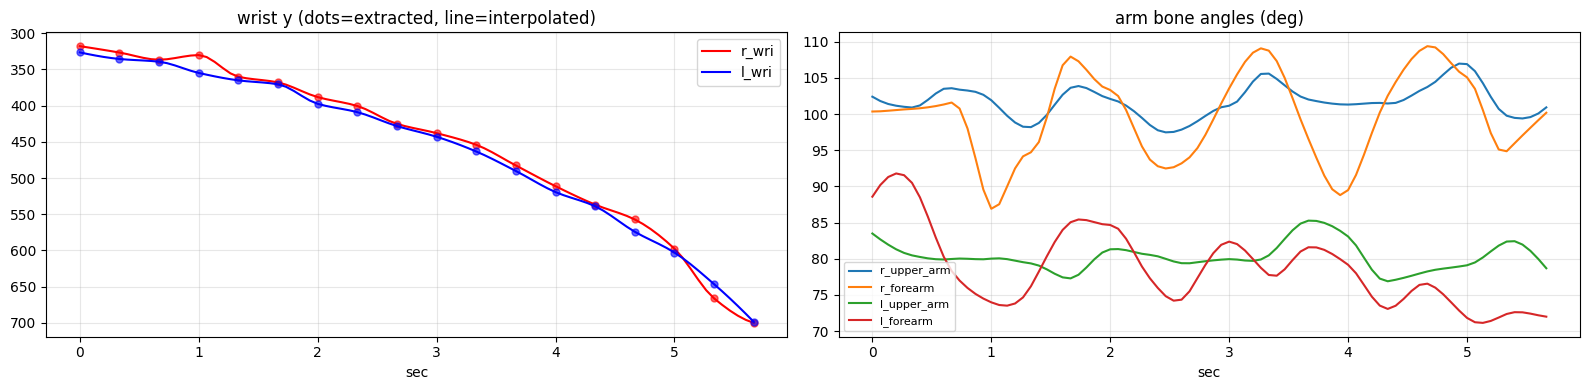

{'torso_ratio': 1.0, 'missing_ratio': 0.0, 'frontal': 0.586, 'facing': 'front', 'planar_ratio': 1.0, 'usable': True, 'best_camera': True}


In [ ]:
import matplotlib.pyplot as plt
from IPython.display import Video, display

best = [s for s in summary if s["best_camera"]]
print("고른 동작:", [f"[{i}] {s['seq']}" for i, s in enumerate(best)])
CHECK = 0                                     # 볼 동작 번호
s = best[CHECK]
stem = re.sub(r"[^\w\-]+", "_", s["seq"])
r = json.loads((OUT_DIR / "motions" / f"{stem}.json").read_text(encoding="utf-8").replace("null", "NaN"))
K, A = np.array(r["keypoints_px"], float), np.array(r["bone_angles_deg"], float)
S = np.array(r["keypoints_src_px"], float)
t = np.arange(r["n_frames"]) / r["fps"]
ts = (np.array(r["src_frames"]) - r["src_frames"][0]) / r["src_fps"]

fig, ax = plt.subplots(1, 2, figsize=(16, 4))
for j, c in ((4, "r"), (7, "b")):            # 손목 높이: 점=원본 샘플에서 추출, 선=보간된 동작
    ax[0].plot(ts, S[:, j, 1], c + "o", ms=5, alpha=.6)
    ax[0].plot(t, K[:, j, 1], c + "-", label=J15[j])
ax[0].invert_yaxis(); ax[0].set_title("wrist y (dots=extracted, line=interpolated)"); ax[0].set_xlabel("sec"); ax[0].legend()
for b in (3, 4, 6, 7):                       # 팔 뼈 각도
    ax[1].plot(t, A[:, b], label=r["bones"][b])
ax[1].set_title("arm bone angles (deg)"); ax[1].set_xlabel("sec"); ax[1].legend(fontsize=8)
for a in ax:
    a.grid(alpha=.3)
plt.tight_layout(); plt.show()
print(r["quality"])
for kind in ("frames", "motion"):            # 원본 프레임+관절 / 보간된 동작(막대 인형)
    p = OUT_DIR / "previews" / f"{stem}_{kind}.mp4"
    if p.exists():
        display(Video(str(p), embed=True, width=480))

## 7. 다운로드

In [ ]:
import shutil
from google.colab import files

zip_path = shutil.make_archive("/content/motion_out", "zip", OUT_DIR)
print(zip_path, f"{Path(zip_path).stat().st_size / 1e6:.1f}MB")
files.download(zip_path)

/content/motion_out.zip 1.4MB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>